# 04 · Synthese: Robustheit, alternative Erklärungen und Antwort

**Hauptfrage.** Wie unterscheiden sich die auf Airbnb angebotenen Preise pro Nacht für Inserate in Paris nach Unterkunftsart, Kapazität und Arrondissement, und wie robust sind diese Unterschiede gegenüber extremen Preisen, den Bedingungen der Preisabfrage und Mehrfachinseraten derselben Hosts?

**Was dieses Notebook leistet.** NB03 hat drei Kernaussagen geliefert:

- **A1 Zimmerart:** Ganze Unterkünfte sind teurer als Privatzimmer. Bei gleicher Gästezahl schrumpft der Unterschied aber stark.
- **A2 Kapazität:** Der Preis steigt monoton mit der Kapazität, auch innerhalb jeder Zimmerart.
- **A3 Lage:** Bei fester Zimmerart und Kapazität unterscheiden sich die Arrondissements etwa um den Faktor 2, mit stabiler Rangfolge.

Hier rechnen wir für jede Aussage etwas, das sie **hätte widerlegen können**. Dafür wiederholen wir die Kennzahlen unter **vorab festgelegten Varianten** (Projektvorschlag Abschnitt 4, Schritt 10; `src/daten.py`) und prüfen zwei alternative Erklärungen: den Abfragetermin und die Mehrfach-Hosts.

**Vorlesungsbezug:** VL01 S. 19–21 (Bias), VL02 S. 35, VL04 S. 36 (Drittvariablen), VL06 S. 17, 20, 29, 32–34 (Parameter, Selection Bias, Endlichkeitskorrektur, Bootstrap). TA-Vorlage: NB03_Ausreisserregeln §3 («Sensitivität statt Löschen»).

**Aufbau**

1. Die Prüfkennzahlen
2. Sensitivitätstabelle über alle Varianten
3. Alternative Erklärung I: Abfragetermin
4. Alternative Erklärung II: Mehrfach-Hosts
5. Optional (VL06): Wie stabil sind die Mediane? Bootstrap über Hosts
6. Antwort auf die Hauptfrage
7. Grenzen und offene Punkte

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Projektwurzel finden (Ordner mit src/), damit relative Pfade unabhängig vom Startordner gelten
PROJEKT = Path.cwd().resolve()
while not (PROJEKT / "src").is_dir():
    PROJEKT = PROJEKT.parent
sys.path.insert(0, str(PROJEKT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from scipy import stats

from src import daten as D
from src import grafik as G

G.stil()
SEED = D.SEED
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "'"))

print("Python    ", sys.version.split()[0])
for modul in (np, pd, scipy, matplotlib, sns):
    print(f"{modul.__name__:10s}", modul.__version__)
print("Seed      ", SEED)
print("Snapshot  ", D.SNAPSHOT)

alle, kern, _ = D.bereite_auf()
print(f"\nKern: n = {G.zahl(len(kern))}")

Python     3.14.2
numpy      2.5.4
pandas     3.1.1
scipy      1.18.1
matplotlib 3.11.2
seaborn    0.13.2
Seed       42
Snapshot   2026-09-16



Kern: n = 37'584


---
## 1. Die Prüfkennzahlen

Jede Kernaussage bekommt Kennzahlen, die sie widerlegen könnten:

| Aussage | Kennzahl | Wann wäre die Aussage widerlegt? |
|---|---|---|
| A1 | Verhältnis der Mediane ganze Unterkunft / Privatzimmer, gesamt **und bei 2 Gästen** | Verhältnis bei 2 Gästen ≤ 1 oder stark schwankend |
| A1 | P(oberes Dezil ∣ Zimmerart) mit fester Grenze 643 € (Kern-P90) | Anteile gleich gross oder umgekehrt |
| A2 | Spearman ρ zwischen Gästen und Preis innerhalb ganzer Unterkünfte und innerhalb Privatzimmer | ρ nahe 0 oder negativ |
| A3 | Faktor teuerstes/günstigstes Arrondissement im Segment (ganze Unterkunft, 2 Gäste) und Spearman ρ der Rangfolge zur Hauptanalyse | Faktor nahe 1 oder Rangfolge nicht stabil (ρ klein) |

Die Grenze 643 € bleibt in **allen** Varianten fest. Sonst würde sich die Bezugsgrösse mit jeder Variante verschieben.

In [2]:
GRENZE_OBEN = kern["preis_eur"].quantile(0.9)
SEGMENT_HAUPT = kern[(kern["room_type"] == "Entire home/apt") & (kern["accommodates"] == 2)]
RANG_HAUPT = SEGMENT_HAUPT.groupby("arrondissement")["preis_eur"].median()


def pruefkennzahlen(d: pd.DataFrame) -> pd.Series:
    ganz = d[d["room_type"] == "Entire home/apt"]
    privat = d[d["room_type"] == "Private room"]
    seg = ganz[ganz["accommodates"] == 2]
    lage = seg.groupby("arrondissement")["preis_eur"].median()
    return pd.Series({
        "n": len(d),
        "Median gesamt": d["preis_eur"].median(),
        "Mittelwert gesamt": d["preis_eur"].mean(),
        "Median Ganze U.": ganz["preis_eur"].median(),
        "Median Privatz.": privat["preis_eur"].median(),
        "A1 Verhältnis gesamt": ganz["preis_eur"].median() / privat["preis_eur"].median(),
        "A1 Verhältnis bei 2 Gästen": seg["preis_eur"].median() / privat.loc[privat["accommodates"] == 2, "preis_eur"].median(),
        "A1 P(oben|Ganze U.) %": 100 * (ganz["preis_eur"] > GRENZE_OBEN).mean(),
        "A1 P(oben|Privatz.) %": 100 * (privat["preis_eur"] > GRENZE_OBEN).mean(),
        "A2 ρ Kapazität Ganze U.": ganz["accommodates"].corr(ganz["preis_eur"], method="spearman"),
        "A2 ρ Kapazität Privatz.": privat["accommodates"].corr(privat["preis_eur"], method="spearman"),
        "A3 n Segment": len(seg),
        "A3 Faktor Arr. max/min": lage.max() / lage.min(),
        "A3 ρ Rangfolge vs. Haupt": stats.spearmanr(lage.reindex(RANG_HAUPT.index), RANG_HAUPT).statistic,
    })

---
## 2. Sensitivitätstabelle über alle Varianten

| Variante | Was sie prüft |
|---|---|
| ohne Extrem-Kennzeichnung | Hängen die Aussagen an den 117 zweifelhaften Preisen? (NB02) |
| winsorisiert 99.5 % je Zimmerart | Kappen statt Entfernen. Ändert per Konstruktion keine Mediane und Ränge, nur den Mittelwert. Das ist eine Kontrolle. |
| ohne «nicht verfügbar»-Abfragen | 531 Abfragen ohne Währungsangabe und mit Status «nicht verfügbar» (NB01) |
| ein Inserat pro Host | Mehrfach-Hosts als abhängige Cluster (Seed 42) |
| Check-in ≤ 30 bzw. > 30 Tage nach Scrape | Abfragetermin (Saison und Vorlauf) |
| inkl. Abfragen ≥ 28 Nächte | Die Monatspreise, die wir in NB01 ausgeschlossen haben |

In [3]:
varianten = D.sensitivitaets_varianten(alle, kern)
varianten["Check-in > 30 Tage nach Scrape"] = kern[kern["abfrage_vorlauf_tage"] > 30]

sensitivitaet = pd.DataFrame({name: pruefkennzahlen(d) for name, d in varianten.items()}).T
D.speichere_tabelle(sensitivitaet, "04_sensitivitaet_alle_varianten")
sensitivitaet.round(2)

,n,Median gesamt,Mittelwert gesamt,Median Ganze U.,Median Privatz.,A1 Verhältnis gesamt,A1 Verhältnis bei 2 Gästen,A1 P(oben|Ganze U.) %,A1 P(oben|Privatz.) %,A2 ρ Kapazität Ganze U.,A2 ρ Kapazität Privatz.,A3 n Segment,A3 Faktor Arr. max/min,A3 ρ Rangfolge vs. Haupt
Kern (Hauptanalyse),37'584.00,240.43,367.32,252.00,160.42,1.57,1.14,10.70,5.40,0.60,0.43,12'145.00,2.04,1.00
ohne Extrem-Kennzeichnung,37'467.00,240.00,338.59,251.51,159.00,1.58,1.16,10.53,4.29,0.60,0.44,12'134.00,2.04,1.00
winsorisiert 99.5% je Zimmerart,37'584.00,240.43,348.26,252.00,160.42,1.57,1.14,10.70,5.40,0.60,0.43,12'145.00,2.04,1.00
ohne 'nicht verfügbar'-Abfragen,37'053.00,241.25,369.25,252.00,153.35,1.64,1.21,10.70,5.96,0.60,0.46,12'144.00,2.04,1.00
ein Inserat pro Host,25'382.00,217.75,322.76,229.33,135.00,1.70,1.29,8.22,2.94,0.56,0.46,9'476.00,1.94,1.00
Check-in ≤ 30 Tage nach Scrape,24'236.00,272.00,419.42,289.00,185.00,1.56,1.10,14.39,6.48,0.59,0.39,6'875.00,1.99,0.98
inkl. Abfragen ≥ 28 Nächte,43'537.00,218.00,337.20,226.00,157.96,1.43,1.03,9.28,5.29,0.60,0.44,15'239.00,1.84,0.97
Check-in > 30 Tage nach Scrape,13'348.00,195.50,272.71,203.75,120.67,1.69,1.30,4.46,2.34,0.60,0.57,5'270.00,1.98,0.99


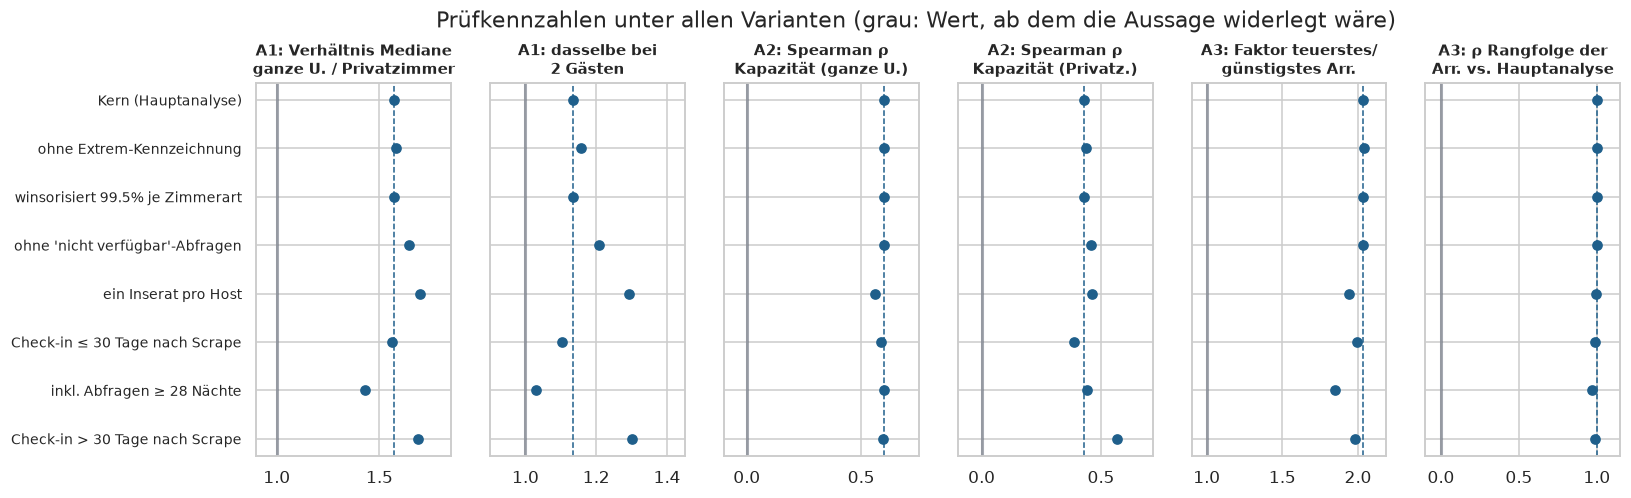

In [4]:
# Darstellen: die Prüfkennzahlen je Variante; gestrichelt = Hauptanalyse, grau = Widerlegungsgrenze
panels = [
    ("A1 Verhältnis gesamt", "A1: Verhältnis Mediane\nganze U. / Privatzimmer", 1.0),
    ("A1 Verhältnis bei 2 Gästen", "A1: dasselbe bei\n2 Gästen", 1.0),
    ("A2 ρ Kapazität Ganze U.", "A2: Spearman ρ\nKapazität (ganze U.)", 0.0),
    ("A2 ρ Kapazität Privatz.", "A2: Spearman ρ\nKapazität (Privatz.)", 0.0),
    ("A3 Faktor Arr. max/min", "A3: Faktor teuerstes/\ngünstigstes Arr.", 1.0),
    ("A3 ρ Rangfolge vs. Haupt", "A3: ρ Rangfolge der\nArr. vs. Hauptanalyse", 0.0),
]
fig, achsen = plt.subplots(1, len(panels), figsize=(16, 4.4), sharey=True)
y = np.arange(len(sensitivitaet))
for ax, (spalte, titel, grenze) in zip(achsen, panels):
    werte = sensitivitaet[spalte]
    ax.plot(werte, y, "o", color=G.FARBEN_ZIMMERART["Entire home/apt"])
    ax.axvline(werte.iloc[0], color=G.FARBEN_ZIMMERART["Entire home/apt"], linestyle="--", linewidth=1)
    ax.axvline(grenze, color=G.GRAU, linewidth=2, alpha=0.6)
    ax.set_title(titel, fontsize=10)
    ax.set_xlim(min(grenze, werte.min()) - 0.1, werte.max() + 0.15)
achsen[0].set_yticks(y, sensitivitaet.index, fontsize=9)
achsen[0].invert_yaxis()
fig.suptitle("Prüfkennzahlen unter allen Varianten (grau: Wert, ab dem die Aussage widerlegt wäre)", y=1.03)
G.speichere(fig, "04_sensitivitaet_pruefkennzahlen")
plt.show()

**Beobachtung**

- **A1:**
  - Das rohe Verhältnis der Mediane liegt in allen Varianten zwischen 1.43 und 1.70.
  - Bei 2 Gästen ist es viel kleiner und schwankt stärker: von **1.03** (inkl. Monatsabfragen) bis **1.30** (Check-in > 30 Tage). Es bleibt aber in jeder Variante über 1.
  - P(oberes Dezil ∣ ganze Unterkunft) ist in jeder Variante 1.8- bis 2.8-mal so gross wie bei Privatzimmern.
- **A2:** ρ innerhalb ganzer Unterkünfte liegt zwischen 0.56 und 0.60, innerhalb der Privatzimmer zwischen 0.39 und 0.57.
- **A3:**
  - Der Faktor zwischen teuerstem und günstigstem Arrondissement liegt zwischen 1.84 und 2.04.
  - Die Rangfolge korreliert in jeder Variante mit ρ ≥ 0.97 mit der Hauptanalyse.
- **Niveau:**
  - Der Gesamtmedian bewegt sich deutlich: 196 € (Check-in > 30 Tage) bis 272 € (Check-in ≤ 30 Tage).
  - Der Mittelwert reagiert vor allem auf die Extremwerte (339 € ohne sie, 367 € mit ihnen).

**Interpretation**

- **Keine Variante widerlegt eine der drei Aussagen.** A2 (Kapazität) und A3 (Lage) sind auch in ihrer Grösse stabil.
- Bei A1 ist nur die **Richtung** stabil. Wie gross der Aufpreis für eine ganze Unterkunft bei gleicher Kapazität ist, hängt von der Variante ab (3 % bis 30 %). Belastbar ist deshalb nur die Aussage «klein, aber positiv».
- **Nicht robust** ist das **Preisniveau**, also die Antwort auf «Was kostet eine Nacht?». Es hängt vor allem vom Abfragetermin und von der Gewichtung der Mehrfach-Hosts ab. Das prüfen die nächsten beiden Abschnitte.

---
## 3. Alternative Erklärung I: Abfragetermin

Jedes Inserat wurde zu einem anderen Termin abgefragt (NB01 Abschnitt 3). Unterscheiden sich die Gruppen im **Termin**, könnte ein Gruppenunterschied in Wahrheit ein Saison- oder Vorlaufeffekt sein. Das wäre eine Drittvariable im Sinn von VL04 S. 36.

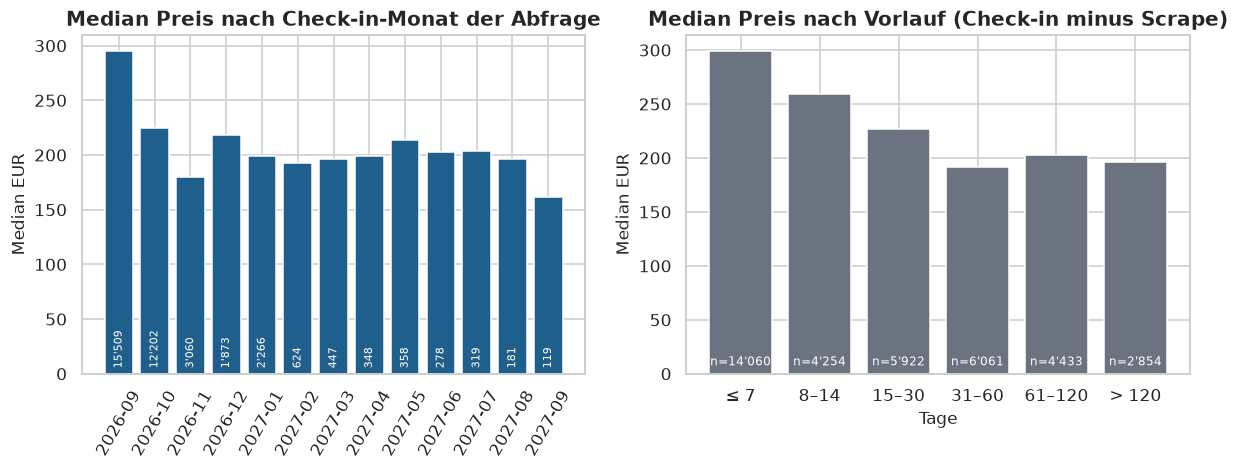

,n,Median
abfrage_vorlauf_tage,,
≤ 7,14060,299.00
8–14,4254,259.01
15–30,5922,226.55
31–60,6061,191.33
61–120,4433,202.67
> 120,2854,196.00


In [5]:
monat = kern["abfrage_checkin"].dt.to_period("M").astype(str)
nach_monat = kern.groupby(monat)["preis_eur"].agg(n="size", Median="median")
vorlauf = pd.cut(kern["abfrage_vorlauf_tage"], [-10, 7, 14, 30, 60, 120, 400],
                 labels=["≤ 7", "8–14", "15–30", "31–60", "61–120", "> 120"])
nach_vorlauf = kern.groupby(vorlauf, observed=True)["preis_eur"].agg(n="size", Median="median")

fig, achsen = plt.subplots(1, 2, figsize=(13, 4))
achsen[0].bar(nach_monat.index, nach_monat["Median"], color=G.FARBEN_ZIMMERART["Entire home/apt"])
achsen[0].tick_params(axis="x", rotation=60)
achsen[0].set(title="Median Preis nach Check-in-Monat der Abfrage", ylabel="Median EUR")
for i, n in enumerate(nach_monat["n"]):
    achsen[0].text(i, 5, G.zahl(n), ha="center", va="bottom", fontsize=7, color="white", rotation=90)
achsen[1].bar(nach_vorlauf.index.astype(str), nach_vorlauf["Median"], color=G.GRAU)
achsen[1].set(title="Median Preis nach Vorlauf (Check-in minus Scrape)", xlabel="Tage", ylabel="Median EUR")
for i, n in enumerate(nach_vorlauf["n"]):
    achsen[1].text(i, 5, f"n={G.zahl(n)}", ha="center", va="bottom", fontsize=8, color="white")
G.speichere(fig, "04_abfragetermin")
plt.show()
display(nach_vorlauf)

In [6]:
# Ist der Termin zwischen den Gruppen ungleich verteilt?
frueh = kern["abfrage_vorlauf_tage"] <= 30
termin_art = (100 * frueh.groupby(kern["zimmerart"], observed=True).mean()).round(1).rename("Anteil Check-in ≤ 30 Tage (%)")
display(termin_art.to_frame())

seg = SEGMENT_HAUPT
anteil_frueh_arr = seg["abfrage_vorlauf_tage"].le(30).groupby(seg["arrondissement"]).mean()
rho_termin_lage = stats.spearmanr(anteil_frueh_arr, RANG_HAUPT[anteil_frueh_arr.index]).statistic
print(f"Segment (2 Gäste): Anteil früher Check-ins je Arrondissement zwischen {anteil_frueh_arr.min():.0%} und {anteil_frueh_arr.max():.0%}")
print(f"Spearman ρ zwischen diesem Anteil und dem Median-Preis des Arrondissements: {rho_termin_lage:.2f}")

# Gegenprobe: Rangfolge der Arrondissements getrennt innerhalb früher und später Check-ins
rang_frueh = seg[seg["abfrage_vorlauf_tage"] <= 30].groupby("arrondissement")["preis_eur"].median()
rang_spaet = seg[seg["abfrage_vorlauf_tage"] > 30].groupby("arrondissement")["preis_eur"].median()
print(f"ρ der Arrondissement-Rangfolge früh vs. spät: {stats.spearmanr(rang_frueh, rang_spaet[rang_frueh.index]).statistic:.2f}")

,Anteil Check-in ≤ 30 Tage (%)
zimmerart,
Entire home/apt,62.80
Private room,73.90
Hotel room,85.70
Shared room,94.90


Segment (2 Gäste): Anteil früher Check-ins je Arrondissement zwischen 49% und 70%
Spearman ρ zwischen diesem Anteil und dem Median-Preis des Arrondissements: 0.39
ρ der Arrondissement-Rangfolge früh vs. spät: 0.98


**Beobachtung**

- Der Abfragetermin hängt stark mit dem Preis zusammen. Bei Abfragen mit höchstens 7 Tagen Vorlauf liegt der Median bei 299 € (n = 14 060), bei 31–60 Tagen Vorlauf bei 191 € (n = 6 061). Nach Check-in-Monat ist der September 2026 klar am teuersten.
- Die Gruppen sind **unterschiedlich** über die Termine verteilt. Privatzimmer wurden häufiger kurzfristig abgefragt (74 %) als ganze Unterkünfte (63 %). Bei den Arrondissements hängt der Anteil früher Check-ins mässig mit dem Preisniveau zusammen.
- Trotzdem bleiben die Aussagen **innerhalb** gleicher Terminfenster bestehen (Tabelle in Abschnitt 2):
  - Verhältnis ganze Unterkunft / Privatzimmer: 1.56 (früh) bzw. 1.69 (spät), bei 2 Gästen 1.10 bzw. 1.30
  - ρ Kapazität bei ganzen Unterkünften: 0.59 bzw. 0.60
  - Faktor zwischen den Arrondissements: 1.99 bzw. 1.98
  - Die Rangfolge der Arrondissements korreliert zwischen früh und spät mit ρ = 0.98.

**Interpretation**

- Der Termin ist eine **echte Störgrösse für das Preisniveau**. Mit unserem Datensatz lässt sich nicht trennen, ob dahinter Saison (September als Hochsaison), kurzfristige Preissetzung oder eine Auswahl von Inseraten mit frühem freiem Termin steckt. Das bleibt **Vermutung**.
- Für die **Gruppenunterschiede** ist der Termin keine ausreichende Erklärung, denn sie bleiben in beiden Terminfenstern bestehen.
- Ein Satz wie «Eine Nacht in Paris kostet im Median 240 €» gilt deshalb nur mit dem Zusatz «für die abgefragten Termine, überwiegend September und Oktober 2026».

---
## 4. Alternative Erklärung II: Mehrfach-Hosts

Hosts mit vielen Inseraten setzen im Median höhere Preise (NB01 Abschnitt 8) und stellen knapp 20 % des Kerns. Ihre Inserate sind zudem nicht unabhängig voneinander.

In [7]:
host_klasse = pd.cut(kern["inserate_des_hosts"], [0, 1, 2, 9, 10_000], labels=["1", "2", "3–9", "≥ 10"])
host_art = pd.crosstab(kern["zimmerart"], host_klasse, normalize="index").mul(100).round(1)
host_art.columns = [f"Host mit {c} Inseraten (%)" for c in host_art.columns]
display(host_art)

pro_host = varianten["ein Inserat pro Host"]
print(f"Ein Inserat pro Host: n = {G.zahl(len(pro_host))} (von {G.zahl(len(kern))}), Seed {SEED}")
# Hängt das Ergebnis am Seed? Drei weitere Ziehungen
for s in [1, 2, 3]:
    k = pruefkennzahlen(D.ein_inserat_pro_host(kern, seed=s))
    print(f"  Seed {s}: Median gesamt {k['Median gesamt']:.1f}, A1 bei 2 Gästen {k['A1 Verhältnis bei 2 Gästen']:.2f}, "
          f"A2 ρ ganze U. {k['A2 ρ Kapazität Ganze U.']:.3f}, A3 Faktor {k['A3 Faktor Arr. max/min']:.2f}")

,Host mit 1 Inseraten (%),Host mit 2 Inseraten (%),Host mit 3–9 Inseraten (%),Host mit ≥ 10 Inseraten (%)
zimmerart,,,,
Entire home/apt,61.20,7.00,10.50,21.30
Private room,37.40,19.40,35.10,8.00
Hotel room,1.90,9.80,63.50,24.80
Shared room,21.20,10.20,38.10,30.50


Ein Inserat pro Host: n = 25'382 (von 37'584), Seed 42
  Seed 1: Median gesamt 218.0, A1 bei 2 Gästen 1.29, A2 ρ ganze U. 0.560, A3 Faktor 1.90


  Seed 2: Median gesamt 218.0, A1 bei 2 Gästen 1.30, A2 ρ ganze U. 0.559, A3 Faktor 1.94
  Seed 3: Median gesamt 217.5, A1 bei 2 Gästen 1.32, A2 ρ ganze U. 0.561, A3 Faktor 1.99


**Beobachtung**

- Mit nur einem Inserat pro Host sinkt der Gesamtmedian von 240 € auf 218 €.
- Die Prüfkennzahlen bleiben im selben Bereich. Das Verhältnis der Zimmerarten steigt sogar leicht (1.70), ρ bleibt 0.56, der Faktor zwischen den Arrondissements 1.94.
- Andere Seeds (1, 2, 3) verändern die Prüfkennzahlen nur in der zweiten Nachkommastelle.

**Interpretation**

- Die Mehrfach-Hosts **heben das Preisniveau** im Datensatz an. Wer Inserate zählt, misst zu einem guten Teil das Angebot professioneller Anbieter.
- Die **Gruppenunterschiede** werden nicht von einzelnen grossen Hosts getragen.

---
## 5. Optional (VL06): Wie stabil sind die Mediane? Bootstrap über Hosts

**Braucht es hier überhaupt Inferenz?**

- Unsere Daten sind keine Zufallsstichprobe, sondern **fast eine Vollerhebung** der zum Scrape-Zeitpunkt gefundenen und buchbaren Inserate.
- Für die Beschreibung **genau dieses Snapshots** ist der Median eine feste Zahl. Ein Konfidenzintervall wäre hier nicht sinnvoll. Die Endlichkeitskorrektur aus VL06 S. 29 würde es bei n ≈ N gegen null schrumpfen lassen.

**Was ein Intervall trotzdem zeigen kann.** Wir fassen den Snapshot als eine Realisierung eines Prozesses auf, der vergleichbare Angebote erzeugt, etwa an einem ähnlichen Stichtag. Gefragt ist, wie stark der Median schwanken würde, wenn andere **Hosts** mit ihren Inseraten in den Daten wären.

- **Parameter:** der Median des Preises je Zimmerart und das Verhältnis der beiden Mediane in diesem gedachten Prozess.
- **Zufallsannahme:** Die Hosts sind unabhängig, die Inserate innerhalb eines Hosts nicht. Deshalb ziehen wir **ganze Hosts mit Zurücklegen** (Cluster-Bootstrap), nicht einzelne Inserate.
- **Was das Intervall nicht leistet:** Es behebt **keinen** Selection Bias (VL06 S. 20). Die fehlenden Preise, der Abfragetermin und die Suche von Inside Airbnb bleiben unberücksichtigt. Das Intervall ist also ein **Stabilitätsmass**, keine Aussage über «alle Airbnbs in Paris».

In [8]:
def cluster_bootstrap(d: pd.DataFrame, wiederholungen: int = 1000, seed: int = SEED) -> pd.DataFrame:
    d = d.reset_index(drop=True)
    codes, hosts = pd.factorize(d["host_id"])
    reihenfolge = np.argsort(codes, kind="stable")              # Zeilen nach Host sortiert
    start = np.searchsorted(codes[reihenfolge], np.arange(len(hosts)))
    groesse = np.diff(np.r_[start, len(d)])
    preis = d["preis_eur"].to_numpy()
    ist_ganz = (d["room_type"] == "Entire home/apt").to_numpy()
    rng = np.random.default_rng(seed)
    ergebnisse = []
    for _ in range(wiederholungen):
        gezogen = rng.integers(0, len(hosts), len(hosts))       # Hosts mit Zurücklegen
        l = groesse[gezogen]
        # alle Zeilen der gezogenen Hosts einsammeln (vektorisiert)
        idx = reihenfolge[np.repeat(start[gezogen] - np.r_[0, np.cumsum(l)[:-1]], l) + np.arange(l.sum())]
        m_ganz = np.median(preis[idx][ist_ganz[idx]])
        m_privat = np.median(preis[idx][~ist_ganz[idx]])
        ergebnisse.append((m_ganz, m_privat, m_ganz / m_privat))
    return pd.DataFrame(ergebnisse, columns=["Median Ganze U.", "Median Privatz.", "Verhältnis"])

haupt = kern[kern["room_type"].isin(["Entire home/apt", "Private room"])]
boot = cluster_bootstrap(haupt)
punkt = pd.Series({
    "Median Ganze U.": haupt.loc[haupt["room_type"] == "Entire home/apt", "preis_eur"].median(),
    "Median Privatz.": haupt.loc[haupt["room_type"] == "Private room", "preis_eur"].median(),
})
punkt["Verhältnis"] = punkt["Median Ganze U."] / punkt["Median Privatz."]
intervall = pd.DataFrame({
    "Schätzwert": punkt,
    "2.5 %": boot.quantile(0.025),
    "97.5 %": boot.quantile(0.975),
})
D.speichere_tabelle(intervall, "04_cluster_bootstrap")
print(f"Cluster-Bootstrap über {G.zahl(haupt['host_id'].nunique())} Hosts, 1000 Wiederholungen, Seed {SEED}")
intervall.round(2)

Cluster-Bootstrap über 25'300 Hosts, 1000 Wiederholungen, Seed 42


,Schätzwert,2.5 %,97.5 %
Median Ganze U.,252.00,248.25,257.00
Median Privatz.,160.42,154.00,167.27
Verhältnis,1.57,1.50,1.65


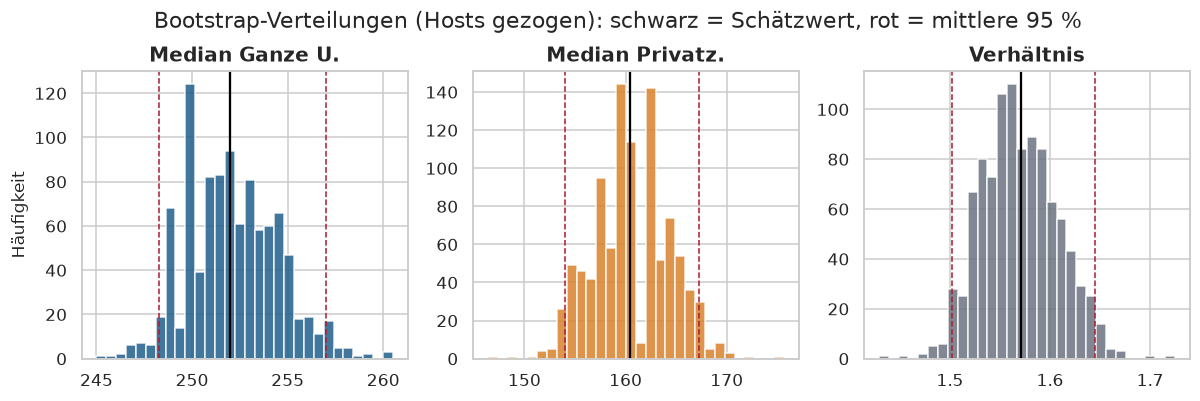

In [9]:
fig, achsen = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, spalte, farbe in zip(achsen, boot.columns, [G.FARBEN_ZIMMERART["Entire home/apt"], G.FARBEN_ZIMMERART["Private room"], G.GRAU]):
    ax.hist(boot[spalte], bins=30, color=farbe, alpha=0.85)
    ax.axvline(punkt[spalte], color="black", linewidth=1.5)
    for q in [0.025, 0.975]:
        ax.axvline(boot[spalte].quantile(q), color=G.AKZENT, linestyle="--", linewidth=1)
    ax.set(title=spalte, ylabel="Häufigkeit" if spalte == boot.columns[0] else None)
fig.suptitle("Bootstrap-Verteilungen (Hosts gezogen): schwarz = Schätzwert, rot = mittlere 95 %", y=1.04)
G.speichere(fig, "04_cluster_bootstrap")
plt.show()

**Beobachtung**

- Das 95-%-Bootstrap-Intervall für den Median der ganzen Unterkünfte liegt bei etwa 248–257 €, für Privatzimmer bei 154–167 €.
- Für das Verhältnis der Mediane ergibt sich 1.50–1.65.

**Interpretation.** Selbst wenn andere Hosts im Datensatz gewesen wären, bliebe der Unterschied zwischen den Zimmerarten deutlich über 1. Die **Stichprobenschwankung** ist hier viel kleiner als die **systematischen Einflüsse** aus Abschnitt 3 und 4: Der Abfragetermin verschiebt den Median ganzer Unterkünfte zwischen 204 € und 289 €. Das ist die Merksatz-Situation aus VL06 S. 20: Mehr Daten oder ein schmales Intervall helfen gegen keinen Bias.

---
## 6. Antwort auf die Hauptfrage

**Datenbasis.** Angebotene Abfragepreise pro Nacht in EUR für 37 584 buchbare Pariser Airbnb-Inserate von 25 382 Hosts (Snapshot September 2026). Die Abfragen umfassen weniger als 28 Nächte, die Check-ins liegen überwiegend im September und Oktober 2026. Es handelt sich nicht um bezahlte Preise, Umsatz oder Nachfrage.

**Unterkunftsart**

- Ganze Unterkünfte kosten im Median das **1.57-Fache** von Privatzimmern (252 € gegenüber 160 €).
- Der grösste Teil davon geht auf die **Grösse** zurück: Bei gleicher Gästezahl beträgt der Aufpreis nur noch **10 bis 27 %** (Hauptanalyse, 1–4 Gäste). Je nach Robustheitsvariante liegt er bei 2 Gästen zwischen 3 % und 30 %. Belastbar ist nur «klein, aber positiv».
- Die Verteilungen überlappen stark: 27 % der Privatzimmer sind teurer als die typische ganze Unterkunft.

**Kapazität**

- Der Preis steigt **monoton, aber weniger als proportional** mit der Gästezahl.
- Spearman ρ beträgt 0.60 bei ganzen Unterkünften und 0.43 bei Privatzimmern, innerhalb jeder Zimmerart gleichgerichtet.

**Lage**

- Bei gleicher Zimmerart und Kapazität (ganze Unterkunft für 2 Gäste) reichen die Arrondissement-Mediane von **133 € (Ménilmontant) bis 271 € (Louvre)**, also um den **Faktor 2**.
- Die Extreme überlappen kaum, die Mitte stark.

**Robustheit**

- Alle drei Aussagen überstehen in ihrer Richtung jede vorab festgelegte Variante: ohne Extremwerte, mit nur einem Inserat pro Host, getrennt nach Abfragetermin und mit Monatsabfragen. Kapazität und Lage sind auch in ihrer Grösse stabil, der Zimmerart-Aufpreis bei gleicher Kapazität nicht.
- **Nicht robust** ist das **Preisniveau** selbst. Je nach Abfragetermin und Gewichtung der Hosts liegt der Gesamtmedian zwischen etwa 196 € und 272 €.
- Mittelwert und Pearson r hätten wegen weniger zweifelhafter Extrempreise ein verzerrtes Bild ergeben. Median und Rangmasse bleiben davon unberührt.

**Kurzfassung für eine Folie:**
> Lage und Grösse prägen den angebotenen Preis stärker als die Unterkunftsart allein. Diese Unterschiede sind robust, das absolute Preisniveau dagegen hängt stark davon ab, wann und wie abgefragt wurde.

---
## 7. Grenzen und offene Punkte

1. **Selektion.** 43.6 % der Inserate haben keinen Preis, vor allem nicht buchbare. Ob das Fehlen auch vom (unbekannten) Preis abhängt (MNAR), lässt sich nicht prüfen. Die Aussagen gelten nur für buchbar angebotene Inserate.
2. **Messung.** Der Preis ist eine Abfrage für einen Termin, nicht ein bezahlter Preis. Gebühren und Steuern fehlen meist. Die Abfragefelder sind im Data Dictionary v4.3 nicht dokumentiert, ihre Bedeutung haben wir aus den Daten erschlossen.
3. **Termin.** Die Saison und die Termine verfügbarer Nächte lassen sich nicht trennen. Mit `calendar.csv.gz` liesse sich das eventuell prüfen, falls dort Preise je Datum vorliegen (nicht untersucht).
4. **Drittvariablen.** Die Schichtung hält jeweils nur eine Grösse fest. Gleichzeitige Kontrolle mehrerer Grössen wäre Regression (VL10/11). Kausal ist keine der Aussagen.
5. **Extremwerte.** Ob die 117 gekennzeichneten Preise Fehler, Sperrpreise oder Luxusangebote sind, bleibt ohne externe Quelle offen. Für die Aussagen spielt das keine Rolle (Abschnitt 2).
6. **Einzelner Snapshot.** Über Veränderungen über die Zeit sagen die Daten nichts.